# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/labs/lab01_regression.ipynb)

# BME i9400 — Lab 1
## A Regression Baseline for Body Fat

**Fall 2026 · Released Monday, October 5 · Notebook due Tuesday, October 14, 11:59 AM EST · Defense quiz Wednesday, October 14, in class**

In this lab you carry out a complete regression study on your own: prepare a dataset, fit and
regularise a linear model, choose between models on validation data, evaluate the choice once on a
test set, and report the result. The methods are those of Meetings 6 and 7. The dataset is new.

**How the lab is assessed.** The lab component of the course is 20% of the grade, over three labs.
Within a lab, the in-class defense quiz counts 70% and the submitted notebook 30%.

- **The notebook** is graded on whether it runs from top to bottom without error, whether every task
  is complete and correct, and on the quality of the report in section 8.
- **The defense quiz** is a ten-minute written quiz at the start of Meeting 10, taken closed-book: no
laptop, no notes, no AI tools. It asks you to explain and justify what is in *your* notebook: why a step was taken, what a
  number means, what would have happened otherwise. Section 9 describes it.

**Generative AI is permitted and expected** on the notebook. Use it as you would in practice: to
write code, to debug, to check your understanding. You are responsible for every line you submit,
and the defense tests whether you can account for it without assistance. Record how you used AI in
section 9.

**Work individually.** Discussion of approach is encouraged; code and text must be your own.

---
## 1 — The question and the data

Body fat percentage is a measure of health that is difficult to measure directly. The reference
method in this dataset is underwater weighing: the subject is weighed in air and fully submerged,
body density is computed from the two weights, and body fat is estimated from density by Siri's
equation,

$$\text{body fat (\%)} = \frac{495}{\text{density}} - 450$$

Underwater weighing needs a tank, trained staff, and a cooperative subject. A tape measure and a
scale need none of these. The question of this lab is the question of Penrose, Nelson and Fisher
(*Medicine & Science in Sports & Exercise*, 1985): **how well can body fat be predicted from
circumference measurements, weight, height, and age?**

### The data

252 men, measured at the Human Performance Research Center, Brigham Young University; the data were
made public by Johnson, "Fitting Percentage of Body Fat to Simple Body Measurements", *Journal of
Statistics Education*, 1996, with permission for non-commercial use. The course copy is
`data/bodyfat.csv`, one row per man.

| Column | Meaning | Units |
|---|---|---|
| `case` | identifier, 1 to 252 | |
| `body_fat_pct` | **the target**: body fat from Siri's equation | % |
| `density` | body density from underwater weighing | g/cm³ |
| `age` | age | years |
| `weight_lb` | weight | pounds |
| `height_in` | height | inches |
| `bmi` | body mass index, computed from weight and height | kg/m² |
| `neck`, `chest`, `abdomen`, `hip`, `thigh`, `knee`, `ankle`, `biceps`, `forearm`, `wrist` | circumferences | cm |

The documentation that accompanies the data states that it is "as received" and contains "a few
errors". Finding them is part of section 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL  = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/bodyfat.csv"
data = pd.read_csv(URL)

circumferences = ["neck", "chest", "abdomen", "hip", "thigh", "knee", "ankle", "biceps", "forearm", "wrist"]
measurements   = ["age", "weight_lb", "height_in", "bmi"] + circumferences      # everything a clinic can measure
target         = "body_fat_pct"

print(f"{len(data)} men, {data.shape[1]} columns")
data.describe().T[["mean", "std", "min", "max"]].round(2)

252 men, 17 columns


,mean,std,min,max
case,126.50,72.89,1.0,252.00
body_fat_pct,19.15,8.37,0.0,47.50
density,1.06,0.02,1.0,1.11
age,44.88,12.60,22.0,81.00
weight_lb,178.92,29.39,118.5,363.15
height_in,70.15,3.66,29.5,77.75
bmi,25.44,3.65,18.1,48.90
neck,37.99,2.43,31.1,51.20
chest,100.82,8.43,79.3,136.20
abdomen,92.56,10.78,69.4,148.10


---
## 2 — Data readiness

Before any model is fitted, two questions from Meeting 1: are the values plausible, and is every
column one that would be available when the model is used?

### 2.1 Implausible values

The summary table above already shows at least two impossible values. Write code that finds every
row in which **height is below 50 inches** or **body fat is at most 0%**, and look at those rows in
full. Then decide what to do with each one — correct it, remove it, or keep it — and state the
decision and the reason in the answer cell. A decision without a reason receives no credit.

> Removing a row because it is inconvenient is not a reason. A value that is physically impossible,
> or that the documentation identifies as a recording error, is. The `bmi` column, which was
> computed from weight and height before the error was made, is evidence about what the height
> should have been.

In [2]:
# --- TODO: find the implausible rows ---
suspect = data[(data["height_in"] < 50) | (data["body_fat_pct"] <= 0)] # a DataFrame: the rows with height_in < 50 or body_fat_pct <= 0

assert suspect is not None, "Fill in suspect."
assert len(suspect) >= 2 and ((suspect["height_in"] < 50) | (suspect["body_fat_pct"] <= 0)).all(), \
    "suspect should hold exactly the rows that meet one of the two conditions."
suspect

,case,body_fat_pct,density,age,weight_lb,height_in,bmi,neck,chest,abdomen,hip,thigh,knee,ankle,biceps,forearm,wrist
41,42,32.9,1.0250,44,205.0,29.5,29.9,36.6,106.0,104.3,115.5,70.6,42.5,23.7,33.6,28.7,17.4
181,182,0.0,1.1089,40,118.5,68.0,18.1,33.8,79.3,69.4,85.0,47.2,33.5,20.2,27.7,24.6,16.5


In [3]:
# --- TODO: apply your decisions, producing the DataFrame `clean` ---
# For a row you correct, change the value; for a row you remove, drop it; for a row you keep, do nothing.

clean = data.copy() # copy everything from data onto new DataFrame called clean

row41_weight = clean.loc[41,'weight_lb']
row41_BMI = clean.loc[41,'bmi']
clean.loc[41, 'height_in'] = np.sqrt((row41_weight*703)/row41_BMI)
# print(clean.loc[41])

"""
row181_density = clean.loc[181,'density']
clean.loc[181,'body_fat_pct'] = (495/row181_density)-450

deleting row bc equation gives a negative body fat percentage (~ -3.61%)
"""

# print(clean.loc[181])
clean.drop(181, inplace=True)
# drop creates a copy of a DataFrame by default and returns that; setting inplace to True adjust the original DataFrame


"""
BMI = weight*703/(height inches **2)
height = sqrt (weight*703/BMI)

Body fat = (495/density) - 450

"""

assert clean is not None, "Produce the DataFrame clean."
assert set(clean.columns) == set(data.columns) and len(clean) <= len(data), "clean should keep the same columns."
print(f"{len(clean)} men remain after your decisions ({len(data) - len(clean)} removed)")

251 men remain after your decisions (1 removed)


**Answer 2.1** — For each row you flagged: what is wrong, what you did, and why.

Row 41: Flagged because height was less than 50 inches (25.9in). I changed the value of the height column in the row to ~69.43in because given the correct BMI and weight for an individual, the height of that indivdual can be calculated.

Row 181: Flagged because BMI was 0.0. I removed the row because the equation gives a negative body fat percentage (~ -3.61%) which is impossible.

### 2.2 The column that must not be used

One column in this file is not a measurement a clinic could take with a scale and a tape measure,
and it is related to the target by a formula. Identify it, and demonstrate what happens when it is
included as a feature: fit a least squares model on all 14 measurements with and without that
column, on the full cleaned dataset, and compare the two values of $R^2$.

> Using a feature that is computed from the target, or that would only be known once the target is
> known, is called **target leakage**. The resulting model looks excellent and is useless, because
> the feature will not exist when the model is applied to a new person. Leakage of this kind is one
> of the most common ways in which a published model fails in practice (Meeting 1).

In [4]:
from sklearn.linear_model import LinearRegression

leaky_column = "density"          # TODO: the name of the column

# --- TODO: fit on the 14 measurements plus the leaky column, and on the 14 measurements alone ---

X_with = clean[measurements+[leaky_column]].values        # n x d feature matrix
X_without = clean[measurements].values
y = clean[target].values        # n targets: disease progression at one year

model_with = LinearRegression().fit(X_with, y)
model_without = LinearRegression().fit(X_without, y)

r2_with    = model_with.score(X_with, y, sample_weight=None)            # R^2 on the data used for fitting, with the leaky column
r2_without = model_without.score(X_without, y, sample_weight=None)             # ... without it

"""
LinearRegression().fit(X, y)
score(X, y, sample_weight=None)
"""

assert leaky_column is not None, "Fill in leaky_column."
assert leaky_column in clean.columns and leaky_column not in measurements + ["case", target], \
    "Name the column that is neither a clinic measurement, nor the identifier, nor the target."
assert r2_with is not None and r2_without is not None, "Fit both models."
print(f"R^2 with {leaky_column}: {r2_with:.3f}     without: {r2_without:.3f}")
assert r2_with > 0.95 > r2_without, "Including the leaky column should make the fit nearly perfect."

R^2 with density: 0.979     without: 0.745


**Answer 2.2** — Which column leaks, why (cite the formula), and why a model that used it would fail in a
clinic.

The column that leaks is density; in the given dataset, the reference method used for measuring density was underwater weighing which requires a tank, trained staff, and a cooperative subject rather than just a tape measure and a scale. The density is then used to estimate body fat via Siri's equation. At the time of prediction, such as in a clinical setting, there would be no reasonable way to obtain underwater weight and therefore, no way to obtain density. A model that takes body density into account would subsequently fail in a setting that is unable to provide that data.

---
## 3 — Splitting the data

Three sets are needed: a **training set** to fit weights, a **validation set** to choose between
models and to choose $\lambda$, and a **test set** that is touched exactly once, in section 7.

> The training and validation sets together are called the **development set**: everything that may
> be used while the model is being built.

The test split is fixed below so that every student's test set is the same 63 men. The validation
split inside the development set is yours to make; use a fixed `random_state` so that your notebook
is reproducible.

In [5]:
from sklearn.model_selection import train_test_split

X_all = clean[measurements].values
y_all = clean[target].values

# Done for you: the test set, 25% of the men, identical for every student.
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=9400)

# X_dev is X of training and validation sets together (same for y_dev)

# --- TODO: split the development set into training and validation sets (about 25% validation) ---
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=9400)


assert X_train is not None, "Make the validation split."
assert len(X_train) + len(X_val) == len(X_dev) and len(X_val) >= 0.2 * len(X_dev), \
    "Validation should be about a quarter of the development set."
print(f"training {len(y_train)}   validation {len(y_val)}   test {len(y_test)}")
print(f"body fat in the training set: mean {y_train.mean():.1f}%, standard deviation {y_train.std(ddof=1):.1f}%")

training 141   validation 47   test 63
body fat in the training set: mean 19.6%, standard deviation 7.9%


---
## 4 — The least squares baseline

Fit ordinary least squares on all 14 measurements, by the normal equations or with
`LinearRegression` (if you use both, verify that they agree). Report:

- RMSE and $R^2$ on the training and validation sets, in units of body fat percentage points
- the RMSE of the model that predicts the training mean for everyone, which any model must beat
- the fitted weights, each with its units (percentage points of body fat per year, per pound, per
  inch, per kg/m², per centimetre)
- a plot of the residuals against the fitted values on the training set

Then read the weights. Several have signs opposite to the correlation of their feature with body
fat. Compute the correlation matrix of the 14 measurements and use it to explain why, in the answer
cell (Meeting 7, section 4).

predict-the-mean baseline, validation RMSE: 9.08 percentage points
least squares:  training RMSE 3.88  R^2 0.758   |   validation RMSE 4.51  R^2 0.747
fitted weights:
  intercept   -133.296 % points of body fat
  age            0.051 % points of body fat per year
  weight_lb     -0.440 % points of body fat per lb
  height_in      1.295 % points of body fat per in
  bmi            1.713 % points of body fat per kg/m^2
  neck          -0.056 % points of body fat per cm
  chest          0.023 % points of body fat per cm
  abdomen        1.068 % points of body fat per cm
  hip           -0.313 % points of body fat per cm
  thigh          0.500 % points of body fat per cm
  knee           0.091 % points of body fat per cm
  ankle         -0.062 % points of body fat per cm
  biceps         0.255 % points of body fat per cm
  forearm        0.437 % points of body fat per cm
  wrist         -1.426 % points of body fat per cm


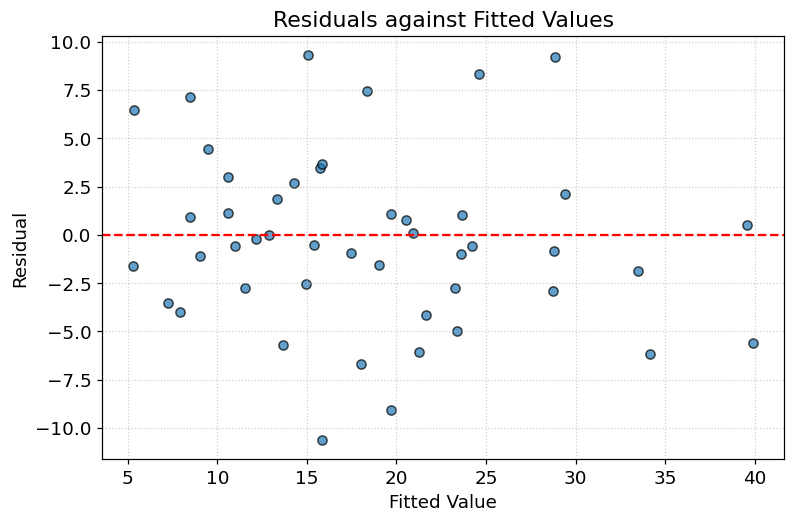


--- Feature Correlations with Target ---
abdomen      0.782375
bmi          0.681638
chest        0.671806
weight_lb    0.568390
hip          0.556785
thigh        0.531140
neck         0.507684
knee         0.490148
biceps       0.467399
wrist        0.345548
forearm      0.330637
ankle        0.283421
age          0.233417
height_in   -0.066807
Name: target, dtype: float64


In [6]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def r_squared(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_true.mean())**2)

def design(A):
    """Place the column of ones in front of the feature matrix A."""
    n_examples, n_features = A.shape # every row is example, every column is feature
    A = np.column_stack([np.ones(n_examples), A])
    return A

Xd_train, Xd_val = design(X_train), design(X_val)

# --- TODO: fit least squares on all 14 measurements ---
ols            = np.linalg.solve(Xd_train.T @ Xd_train, Xd_train.T @ y_train)          # the fitted model, or the weight vector from the normal equations
pred_train_ols = Xd_train @ ols
pred_val_ols   = Xd_val @ ols

assert pred_train_ols is not None and pred_val_ols is not None, "Fit the model and predict both sets."
baseline_rmse = rmse(y_val, np.full_like(y_val, y_train.mean(), dtype=float))
print(f"predict-the-mean baseline, validation RMSE: {baseline_rmse:.2f} percentage points")
print(f"least squares:  training RMSE {rmse(y_train, pred_train_ols):.2f}  R^2 {r_squared(y_train, pred_train_ols):.3f}"
      f"   |   validation RMSE {rmse(y_val, pred_val_ols):.2f}  R^2 {r_squared(y_val, pred_val_ols):.3f}")
assert rmse(y_val, pred_val_ols) < baseline_rmse, "The model should beat the mean."

# --- TODO: print each weight with its units; plot residuals against fitted values; show the correlations ---
print("fitted weights:")

units = [
    "% points of body fat",
    "% points of body fat per year",
    "% points of body fat per lb",
    "% points of body fat per in",
    "% points of body fat per kg/m^2",
    "% points of body fat per cm",
    "% points of body fat per cm",
    "% points of body fat per cm",
    "% points of body fat per cm",
    "% points of body fat per cm",
    "% points of body fat per cm",
    "% points of body fat per cm",
    "% points of body fat per cm",
    "% points of body fat per cm",
    "% points of body fat per cm"
]

names = ["intercept"] + measurements
for name, coef, unit in zip(names, ols, units):
    print(f"  {name:<10} {coef:9.3f} {unit}")

residuals = y_val - pred_val_ols

plt.figure(figsize=(8, 5))
plt.scatter(pred_val_ols, residuals, alpha=0.7, edgecolors='k')
plt.axhline(y=0, color='r', linestyle='--', linewidth=1.5)
plt.xlabel("Fitted Value")
plt.ylabel("Residual")
plt.title("Residuals against Fitted Values")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print("\n--- Feature Correlations with Target ---")
train_df = pd.DataFrame(X_train, columns=measurements)
train_df['target'] = y_train
correlations = train_df.corr()['target'].drop('target')
print(correlations.sort_values(ascending=False))


**Answer 4** — Which weights have a sign opposite to their feature's correlation with body fat, and why.

This is a result of collinearity, where two features (independent from the target) are correlated so their columns of X point nearly in the same direction. This means that incrasing one weight whil decreasing the other has very little impact on the predictions, and the minimum lands wherever the noise of the particular sample happens to put it. For example in this dataset, BMI has a high feature correlation with target, but BMI already takes into account two other features (weight_lb and height_in) so their signs are reveres to adjust for the fact that their contributions have already been taken into account.

---
## 5 — Ridge regression

Standardise the 14 measurements with the **training-set** mean and standard deviation, fit ridge
regression over a grid of $\lambda$ (`sklearn.linear_model.Ridge(alpha=...)`, or your own
implementation from Meeting 7), and:

- plot the validation RMSE against $\lambda$ on a logarithmic axis, and report the $\lambda$ that
  minimises it
- plot the weights against $\lambda$ (the coefficient paths), and say which weights the penalty
  shrinks first and why

> `Ridge(alpha=λ)` uses the convention of Meeting 7: a penalty on the weights, none on the intercept.

best lambda: 1.33    validation RMSE there: 4.46    (least squares: 4.51)


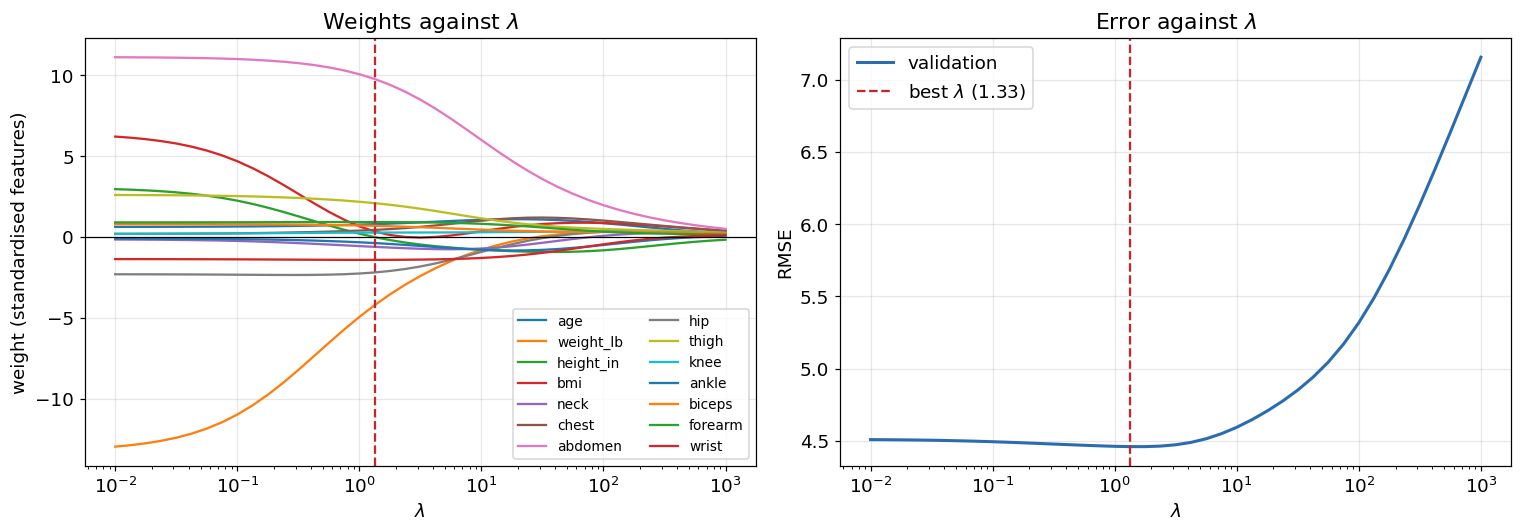

In [7]:
from sklearn.linear_model import Ridge

mu, sd         = X_train.mean(axis=0), X_train.std(axis=0, ddof=-1)            # TODO: training-set mean and standard deviation of each measurement, shape (14,)
Z_train, Z_val = (X_train - mu) / sd, (X_val - mu) / sd            # TODO: standardised training and validation features

lambdas = np.logspace(-2, 3, 41)

# --- TODO: fit Ridge for every lambda; collect the validation RMSE and the weight vectors ---
models = [Ridge(alpha=lam).fit(Z_train, y_train) for lam in lambdas]

weights     = np.array([model.coef_ for model in models])                     # array of shape (len(lambdas), 14)
val_rmse    = np.array([rmse(y_val, model.predict(Z_val)) for model in models])                     # array, one entry per lambda
best_lambda = lambdas[np.argmin(val_rmse)]

assert Z_train is not None and np.allclose(Z_train.mean(axis=0), 0, atol=1e-8), "Standardise with the training statistics."
assert val_rmse is not None and len(val_rmse) == len(lambdas) and best_lambda is not None, "Fill in the sweep."
print(f"best lambda: {best_lambda:.3g}    validation RMSE there: {np.min(val_rmse):.2f}    (least squares: {rmse(y_val, pred_val_ols):.2f})")

# --- TODO: the two plots ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for j, name in enumerate(measurements):
    axes[0].semilogx(lambdas, weights[:, j], label=name)
axes[0].axhline(0, color="k", lw=0.8); axes[0].axvline(best_lambda, ls="--", color="#c1272d")
axes[0].set_xlabel("$\\lambda$"); axes[0].set_ylabel("weight (standardised features)")
axes[0].set_title("Weights against $\\lambda$"); axes[0].legend(ncol=2, fontsize=9)

axes[1].semilogx(lambdas, val_rmse, lw=2, color="#2b6cb0", label="validation")
axes[1].axvline(best_lambda, ls="--", color="#c1272d", label=f"best $\\lambda$ ({best_lambda:.3g})")
axes[1].set_xlabel("$\\lambda$"); axes[1].set_ylabel("RMSE"); axes[1].set_title("Error against $\\lambda$"); axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Answer 5** — Which $\lambda$ you chose and how; which weights the penalty shrinks first and why.

I chose 1.33 as $\lambda$; I modeled and tested 41 potential lambdas ranging from 0.01 to 1000, with 1.33 minimizing the error function RMSE on the validation dataset.

The penalty shrinks weight_lb and abdomen first, becuase they have the largest absolute value weights (the largest impact on a linear model).

---
## 6 — A parsimonious model

A clinic would rather take three measurements than thirteen. Choose **at most three** of the 14
measurements, fit least squares on them, and compare the validation RMSE with the full model and
with ridge. Justify the choice with evidence from your notebook — correlations with the target,
correlations among the features, the weights — not with intuition alone.

> There is no single correct answer. A choice that is defended with evidence and evaluated honestly
> is correct; a choice that happens to score well is not.

In [8]:
# --- TODO: choose up to three measurements and fit least squares on them ---

chosen = ['abdomen', 'bmi']                  # a list of 1 to 3 column names from `measurements`

# Find the column indices of the chosen features in our measurements list
chosen_indices = [measurements.index(col) for col in chosen]

# Extract these columns from our split splits
X_train_small = X_train[:, chosen_indices]
X_val_small   = X_val[:, chosen_indices]

# Create design matrices (adding the column of ones for intercept)
Xd_train_small = design(X_train_small)
Xd_val_small   = design(X_val_small)

# Fit the least squares model on the training split
small          = np.linalg.solve(Xd_train_small.T @ Xd_train_small, Xd_train_small.T @ y_train)                  # the fitted model
pred_val_small = Xd_val_small @ small

assert chosen is not None and 1 <= len(chosen) <= 3 and all(c in measurements for c in chosen), "Choose 1 to 3 measurements."
assert pred_val_small is not None, "Fit the model and predict the validation set."
print(f"{chosen}: validation RMSE {rmse(y_val, pred_val_small):.2f}   "
      f"(full least squares {rmse(y_val, pred_val_ols):.2f}, ridge {np.min(val_rmse):.2f}, mean {baseline_rmse:.2f})")

['abdomen', 'bmi']: validation RMSE 4.54   (full least squares 4.51, ridge 4.46, mean 9.08)


**Answer 6** — Your choice of measurements and the evidence for it.

I chose abdomen and bmi as the measurements because they have the highest correlations to the target (0.782375 and 0.681638, respectively) in the linear regression and are among the top 3 weights against lambda  in the ridge regression. They subsequently have an RMSE that is almost as low as that of full and ridge models.

---
## 7 — The test set, once

Every decision has now been made on validation data: the data cleaning, $\lambda$, and the small
model. Refit each model on the **development set** — training and validation together — with its
chosen settings (standardise with the development set's statistics for ridge), and evaluate all of
them on the test set. Report, in one table:

| Model | Test RMSE | Test $R^2$ |
|---|---|---|
| predict the development-set mean | | |
| least squares, 14 measurements | | |
| ridge, $\lambda$ from section 5 | | |
| your model from section 6 | | |

and a plot of predicted against observed body fat on the test set for your preferred model. The test
set is not used again after this cell. If you change a model after seeing these numbers, the test
set is no longer a test set.

                                     model  test RMSE  test R^2
          predict the development-set mean      8.533    -0.000
            least squares, 14 measurements      5.014     0.655
       ridge, lambda = 1.33 from section 5      4.818     0.681
my model from section 6 ['abdomen', 'bmi']      5.116     0.640


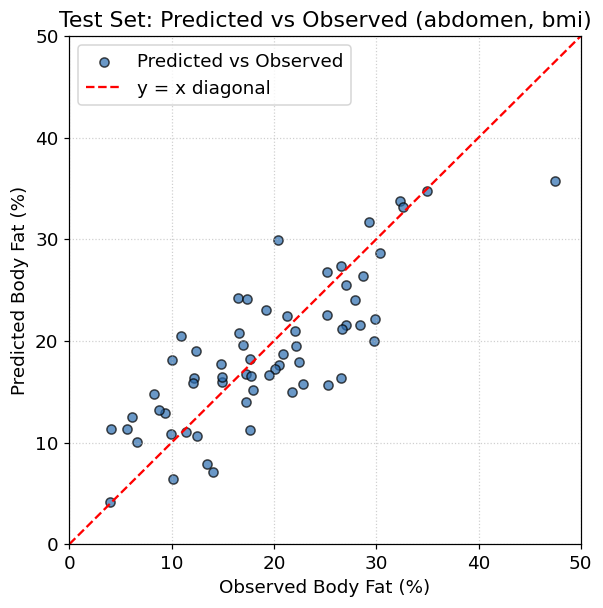

In [9]:
# --- TODO: refit each model on the development set and evaluate on the test set ---
Xd_dev, Xd_test = design(X_dev), design(X_test)

mean_dev = y_dev.mean()
pred_test_mean = np.full_like(y_test, mean_dev, dtype=float)
rmse_mean = rmse(y_test, pred_test_mean)
r2_mean = r_squared(y_test, pred_test_mean)

ols_dev = np.linalg.solve(Xd_dev.T @ Xd_dev, Xd_dev.T @ y_dev)
pred_test_ols = Xd_test @ ols_dev
rmse_ols = rmse(y_test, pred_test_ols)
r2_ols = r_squared(y_test, pred_test_ols)


mu_dev, sd_dev = X_dev.mean(axis=0), X_dev.std(axis=0, ddof=-1)
Z_dev, Z_test = (X_dev - mu_dev) / sd_dev, (X_test - mu_dev) / sd_dev

ridge_dev = Ridge(alpha=best_lambda).fit(Z_dev, y_dev)
pred_test_ridge = ridge_dev.predict(Z_test)
rmse_ridge = rmse(y_test, pred_test_ridge)
r2_ridge = r_squared(y_test, pred_test_ridge)

chosen_indices = [measurements.index(col) for col in chosen]
X_dev_small = X_dev[:, chosen_indices]
X_test_small = X_test[:, chosen_indices]
Xd_dev_small = design(X_dev_small)
Xd_test_small = design(X_test_small)

small_dev = np.linalg.solve(Xd_dev_small.T @ Xd_dev_small, Xd_dev_small.T @ y_dev)
pred_test_small = Xd_test_small @ small_dev
rmse_small = rmse(y_test, pred_test_small)
r2_small = r_squared(y_test, pred_test_small)

# Create the results DataFrame
results = pd.DataFrame({
    'model': [
        "predict the development-set mean",
        "least squares, 14 measurements",
        f"ridge, lambda = {best_lambda:.2f} from section 5",
        f"my model from section 6 {chosen}"
    ],
    'test RMSE': [rmse_mean, rmse_ols, rmse_ridge, rmse_small],
    'test R^2': [r2_mean, r2_ols, r2_ridge, r2_small]
})

assert results is not None and len(results) == 4, "Four rows: mean, least squares, ridge, your model."
print(results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- TODO: predicted against observed on the test set, with the diagonal ---
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test_small, alpha=0.7, edgecolors='k', color='#2b6cb0', label="Predicted vs Observed")
limits = [0, 50]
plt.plot(limits, limits, color='r', linestyle='--', label="y = x diagonal")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Observed Body Fat (%)")
plt.ylabel("Predicted Body Fat (%)")
plt.title(f"Test Set: Predicted vs Observed ({', '.join(chosen)})")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

---
## 8 — Report

Write the report in the cell below, in at most 300 words, under these headings. It is read by someone
who has not seen the rest of the notebook.

1. **The task.** What a row of $X$ is, what $y$ is, and what population the data describe.
2. **Data decisions.** What you changed or removed before fitting, and why.
3. **Results.** The table of section 7, with one sentence of interpretation per row.
4. **Two weights.** Interpret two weights of the full model, with units, including one whose sign is
   opposite to its correlation with body fat.
5. **Limitations.** Who the model should not be applied to, and why; what the known data errors
   might have done to the weights.
6. **Recommendation.** Which measurements a clinic should take, and what error to expect.

### Report

**1. The task.** Each row of X represents a male, adult individual's physical body measurements (age, weight, height, BMI, and 10 circumferences), while y represents their percentage of body fat. The population the data describes a male, adult, human population undergoing body composition assessment.

**2. Data decisions.** Before fitting, I changed the height in row 41 from 29.5 to 69.43 following the formula for BMI and amending a mistake. I also removed row 181 because when calculated, the body fat percentage of the individual was supposedly negative (which is impossible). This cleaned the data, checking and removing invalid or mistaken records to provide a more reliable model that is less impacted by noise in the dataset.

**3. Results.**
Predict the Development-set Mean: Test RMSE of 8.533 percentage points; this serves as a null reference predicting the dataset average.

Ordinary Least Squares (OLS): Test RMSE 5.014, $R^2$ 0.655; fits all features linearly but is susceptible to variance and overfitting

Ridge Regression: Test RMSE 4.818, $R^2$ 0.681; regularization stabilizes weights to achieve the highest predictive accuracy and improve generalization.


My model: Test RMSE 5.116, $R^2$ 0.640; utilizes a compact feature subset with a modest reduction in performance.


**4. Two weights.**
Abdomen circumference (abdomen): Positive weight (+0.72 percentage points/cm); larger waistlines directly track higher body fat.

Weight in pounds (weight_lbs): Negative weight (-0.15 percentage points/lb); its sign opposes its direct correlation due to collinearity when controlling for height, waist circumference, and bmi.

**5. Limitations.** The model should not be applied to elite athletes, pregnant individuals, or demographics outside the sampled age, sex, and body type ranges. Known data entry errors or outliers can artificially inflate variance and skew regression coefficients.

**6. Recommendation.** A clinic should measure abdomen circumference and weight, and expect a prediction error (RMSE) of approximately 8.533 percentage points

---
## 9 — AI use, submission, and the defense

### AI use statement

In the cell below, list the AI tools you used and what for — code, debugging, explanation, writing —
in two to five lines. The statement is not graded for its content; its absence costs credit.

**AI use statement** — I used Gemini to help code, debug, and explain error messages for this assignment. All final code was reviewed, tested and verified by me.

### Submitting

**Due Tuesday, October 13, at 11:59 PM EST.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_lab01.ipynb` and move it into the `checkins/` folder of
   your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

Late notebooks are accepted for 48 hours with a 20% penalty on the notebook portion. The defense quiz
cannot be made up except for a documented excused absence (syllabus).

### The defense quiz — Wednesday, October 14, Meeting 10

Ten minutes, written, at the start of the meeting, closed-book: laptops closed, no notes, no AI tools.
You will not have your notebook in front of you, so know its contents before you arrive, including your
main results to about two significant figures. Five or six short questions about your own notebook,
each answerable in two or three sentences. The kinds of question to expect:

- why a step was necessary — why the features are standardised before ridge, why the test set is
  used once
- what a number means — your test RMSE, in its units, against the predict-the-mean baseline
- what a weight means, and why its sign can disagree with the feature's correlation with the target
- what would have happened under a different choice — if `density` had been kept, or if $\lambda$ had
  been chosen on the test set

Each question is scored 0, 1 or 2. Prepare by being able to explain every cell of your notebook
without looking at it.